- Q1.Does the financial (insurance) type affect patient waiting time?
- Q2.Does the day of the week affect patient waiting time?
- Teacher said I can summit this work without pdf. file. 


1. Setup & load data

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_excel("Hospital_wait(1).xlsx", sheet_name="Source")
df.columns = df.columns.str.strip()
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (29998, 13)


,Date,Medication Revenue,Lab Cost,Consultation Revenue,Doctor Type,Financial Class,Patient Type,Entry Time,Post-Consultation Time,Completion Time,Patient ID,wait time,day
0,2019-11-04,1183.22,10,20.17,ANCHOR,HMO,OUTPATIENT,08:35:45,09:17:54,09:29:46,C10001,00:42:09,Monday
1,2019-11-06,738.48,$-,15,ANCHOR,INSURANCE,OUTPATIENT,19:19:16,21:02:36,21:24:07,C10002,01:43:20,Wednesday
2,2019-11-02,660,$-,21.17,ANCHOR,HMO,OUTPATIENT,10:46:52,11:56:25,12:06:28,C10003,01:09:33,Saturday
3,2019-11-06,600,$-,$-,ANCHOR,MEDICARE,OUTPATIENT,09:38:34,10:55:50,10:58:02,C10004,01:17:16,Wednesday
4,2019-11-01,591.6,$-,12,ANCHOR,INSURANCE,OUTPATIENT,11:16:21,12:06:49,12:06:54,C10005,00:50:28,Friday


2. Understand the dataset

In [ ]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29998 entries, 0 to 29997
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Date                    29998 non-null  datetime64[us]
 1   Medication Revenue      29998 non-null  object        
 2   Lab Cost                29998 non-null  object        
 3   Consultation Revenue    29998 non-null  object        
 4   Doctor Type             29998 non-null  str           
 5   Financial Class         29998 non-null  str           
 6   Patient Type            29998 non-null  str           
 7   Entry Time              29998 non-null  object        
 8   Post-Consultation Time  29998 non-null  object        
 9   Completion Time         29998 non-null  object        
 10  Patient ID              29998 non-null  str           
 11  wait time               29998 non-null  object        
 12  day                     29998 non-null  str           
dt

In [23]:
print("Financial Class:", df["Financial Class"].unique())
print("Day:", df["day"].unique())

Financial Class: <StringArray>
['HMO', 'INSURANCE', 'MEDICARE', 'CORPORATE', 'PRIVATE']
Length: 5, dtype: str
Day: <StringArray>
['Monday', 'Wednesday', 'Saturday', 'Friday', 'Sunday', 'Tuesday', 'Thursday']
Length: 7, dtype: str


3. Compute waiting time = Completion Time − Entry Time

In [24]:
def to_minutes(t):
    return t.hour * 60 + t.minute + t.second / 60

df["wait_min"] = df["Completion Time"].apply(to_minutes) - df["Entry Time"].apply(to_minutes)

print(df["wait_min"].describe().round(1))
print("\nLongest wait:", round(df["wait_min"].max()), "minutes")

count    29998.0
mean        43.8
std         44.4
min          1.0
25%         17.5
50%         31.0
75%         54.4
max        733.5
Name: wait_min, dtype: float64

Longest wait: 734 minutes


4. Q1 — Financial type vs waiting time

Financial Class
MEDICARE     57.9
CORPORATE    46.4
HMO          46.3
INSURANCE    44.3
PRIVATE      39.9
Name: wait_min, dtype: float64


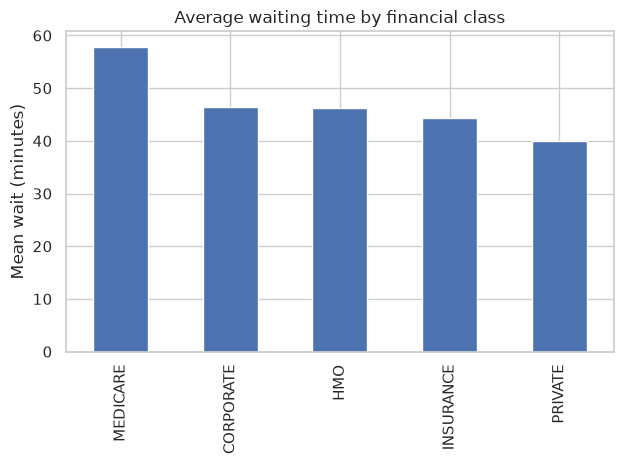

In [25]:
q1 = df.groupby("Financial Class")["wait_min"].mean().sort_values(ascending=False)
print(q1.round(1))

q1.plot(kind="bar", title="Average waiting time by financial class")
plt.ylabel("Mean wait (minutes)"); plt.xlabel(""); plt.tight_layout(); plt.show()

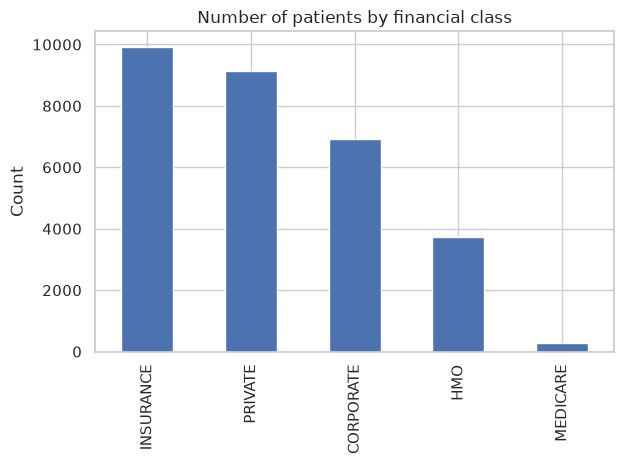

In [30]:
q1 = df.groupby("Financial Class").size().sort_values(ascending=False)
q1.plot(kind="bar", title="Number of patients by financial class")
plt.ylabel("Count"); plt.xlabel(""); plt.tight_layout(); plt.show()

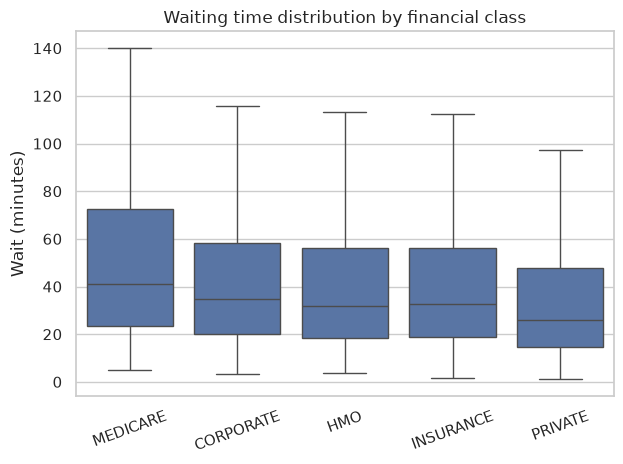

In [27]:
order = q1.index.tolist()
sns.boxplot(data=df, x="Financial Class", y="wait_min", order=order, showfliers=False)
plt.title("Waiting time distribution by financial class"); plt.xlabel(""); plt.ylabel("Wait (minutes)")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

Q1: Waiting time does differ by insurance type. MEDICARE patients
wait the longest and PRIVATE the shortest. 18-minute gap.
MEDICARE has longest wait time may cause by long pathway of checking eligibility not because number of patients.

5. Q2 — Day of the week vs waiting time

day
Monday       49.2
Tuesday      42.5
Wednesday    46.9
Thursday     42.5
Friday       42.5
Saturday     42.5
Sunday       32.8
Name: wait_min, dtype: float64


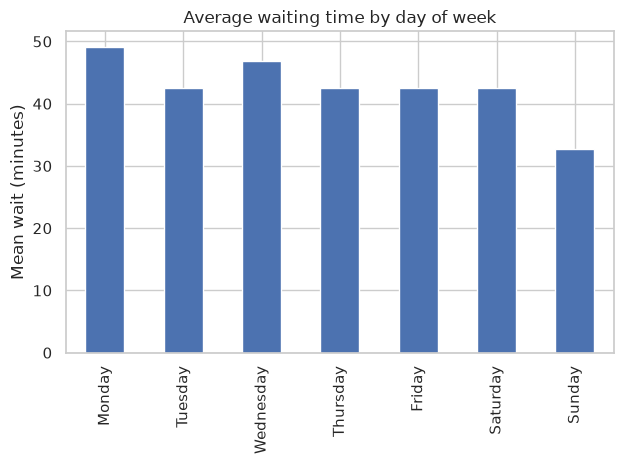

In [28]:
week_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
q2 = df.groupby("day")["wait_min"].mean().reindex(week_order)
print(q2.round(1))

q2.plot(kind="bar", title="Average waiting time by day of week")
plt.ylabel("Mean wait (minutes)"); plt.xlabel(""); plt.tight_layout(); plt.show()

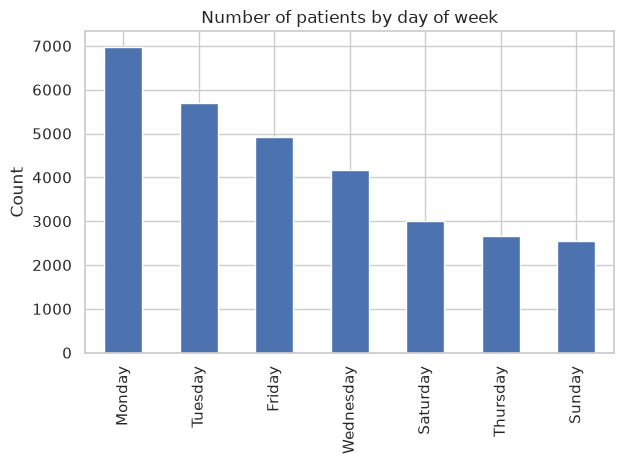

In [31]:
q1 = df.groupby("day").size().sort_values(ascending=False)
q1.plot(kind="bar", title="Number of patients by day of week")
plt.ylabel("Count"); plt.xlabel(""); plt.tight_layout(); plt.show()

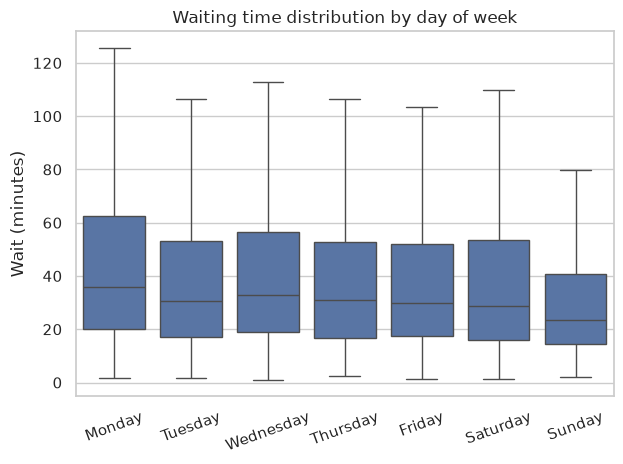

In [ ]:
sns.boxplot(data=df, x="day", y="wait_min", order=week_order, showfliers=False)
plt.title("Waiting time distribution by day of week"); plt.xlabel(""); plt.ylabel("Wait (minutes)")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

Q2: Waiting time does depend on the day. Monday is the busiest 
and the other weekdays is around 45 min, while Sunday is the shortest. 
The waiting distribution is similarly to number of patient distribution that can say number of patient effect the waiting time.


- Q1 Yes: insurance type affects wait (MEDICARE longest, PRIVATE shortest).
- Q2 Yes: day of week affects wait (Monday longest, Sunday shortest).